In [8]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
import os

In [2]:
%pwd

'/Users/lms/Documents/Forschung/textClust'

In [37]:
# Read all files
files = os.listdir("smac3_results_eval_threshold15")
dfs = []
for file in files:
    if file.endswith(".json"):
        df = pd.read_csv(os.path.join("smac3_results_eval_threshold15", file))
        dfs.append(df)
        
df = pd.concat(dfs, ignore_index=True)
df.head()

,dataset,neg_nmi,neg_throughput,config,config_id,loo_dataset,seed
0,examples/data/Semantic10-T.json,-0.770550,-68.809365,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4
1,examples/data/Semantic10-T.json,-0.574116,-1401.232960,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4
2,examples/data/Semantic10-T.json,-0.658934,-1126.828243,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4
3,examples/data/Semantic10-T.json,-0.694323,-1048.154132,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4
4,examples/data/Semantic10-T.json,-0.742763,-884.871232,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4


In [38]:
df["dataset"] = df["dataset"].str.replace("examples/data/", "").str.replace(".json", "")
# Replace "NTSO-T" with "NTSO" (typo in dataset names)
df["dataset"] = df["dataset"].str.replace("NTSO-T", "NTSO")

In [39]:
df["loo_dataset"].unique()

<ArrowStringArray>
[    'Trends-T', 'Semantic40-T',         'SO-T',       'News-T',
           'NT', 'Semantic10-T',  'Semantic5-T',     'Tweets-T',
         'NTSO',          'NTS',         'none']
Length: 11, dtype: str

In [40]:
df_default = df[df["config"] == "default"].copy()
df_no_default = df[df["config"] != "default"].copy()

In [41]:
df_full = df.copy()
df_full = df_full.merge(df_default[["dataset", "neg_nmi", "neg_throughput"]], on="dataset", suffixes=("", "_default"))

df_full["improvement_nmi_over_default"] = -df_full["neg_nmi"] + df_full["neg_nmi_default"]
df_full["improvement_throughput_over_default"] = -df_full["neg_throughput"] + df_full["neg_throughput_default"]
df_full["is_test"] = df_full["loo_dataset"] == df_full["dataset"]

df_full.head()

,dataset,neg_nmi,neg_throughput,config,config_id,loo_dataset,seed,neg_nmi_default,neg_throughput_default,improvement_nmi_over_default,improvement_throughput_over_default,is_test
0,Semantic10-T,-0.770550,-68.809365,best_config_loo_Trends-T_seed_4.json,0,Trends-T,4,-0.663902,-78.897679,0.106648,-10.088313,False
1,Semantic10-T,-0.574116,-1401.232960,best_config_loo_Trends-T_seed_4.json,1,Trends-T,4,-0.663902,-78.897679,-0.089786,1322.335281,False
2,Semantic10-T,-0.658934,-1126.828243,best_config_loo_Trends-T_seed_4.json,2,Trends-T,4,-0.663902,-78.897679,-0.004967,1047.930564,False
3,Semantic10-T,-0.694323,-1048.154132,best_config_loo_Trends-T_seed_4.json,3,Trends-T,4,-0.663902,-78.897679,0.030422,969.256453,False
4,Semantic10-T,-0.742763,-884.871232,best_config_loo_Trends-T_seed_4.json,4,Trends-T,4,-0.663902,-78.897679,0.078861,805.973554,False


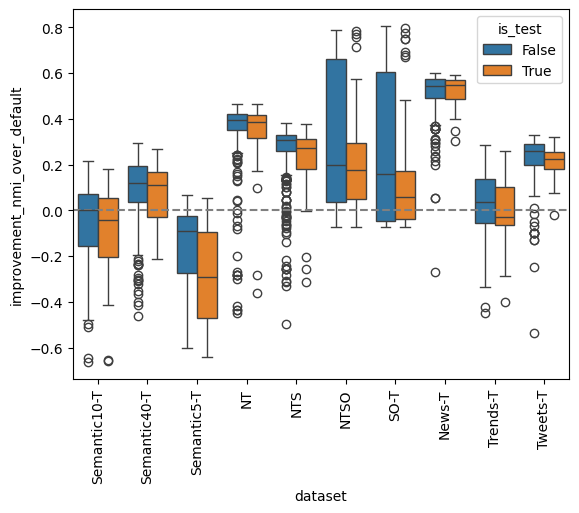

In [42]:
d = df_full[df_full["config"] != "default"].copy()

sns.boxplot(d, x="dataset", y="improvement_nmi_over_default", hue="is_test")
#Rotate x labels
plt.xticks(rotation=90)
# Add zero line
plt.axhline(0, color="grey", linestyle="--")

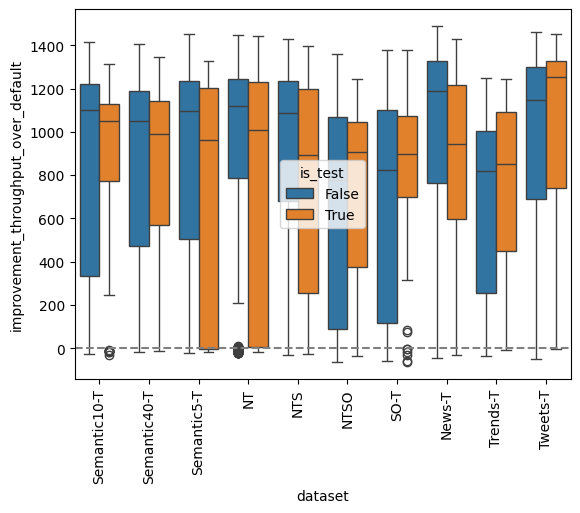

In [43]:
d = df_full[df_full["config"] != "default"].copy()

sns.boxplot(d, x="dataset", y="improvement_throughput_over_default", hue="is_test")
#Rotate x labels
plt.xticks(rotation=90)
# Add zero line
plt.axhline(0, color="grey", linestyle="--")

In [44]:
import numpy as np

def pareto_front(x: np.ndarray, y: np.ndarray) -> np.ndarray:
    """
    Compute the Pareto front of two objective arrays (both minimized).

    Parameters
    ----------
    x : np.ndarray
        1D array of values for the first objective.
    y : np.ndarray
        1D array of values for the second objective.

    Returns
    -------
    np.ndarray
        Boolean mask of shape (n,) where True indicates the point
        is on the Pareto front.
    """
    points = np.stack([x, y], axis=1)  # shape (n, 2)
    n = len(points)
    is_pareto = np.ones(n, dtype=bool)

    for i in range(n):
        if not is_pareto[i]:
            continue
        # A point i is dominated if any other point j is <= in all objectives
        # and strictly < in at least one
        dominated_by_i = (
            np.all(points[i] <= points, axis=1) &   # i dominates others
            np.any(points[i] <  points, axis=1)
        )
        dominated_by_i[i] = False                    # exclude self
        is_pareto[dominated_by_i] = False            # mark dominated points

    return is_pareto

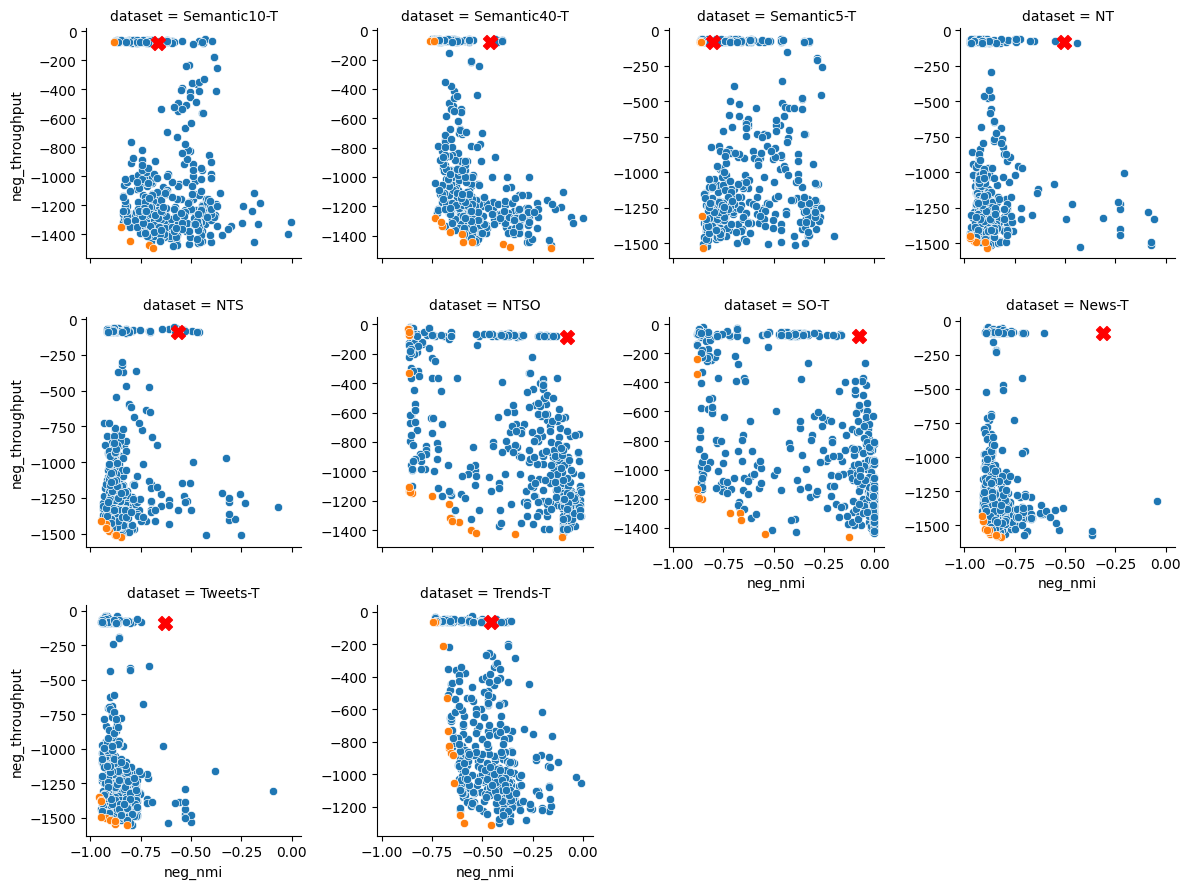

In [45]:
# Compute Pareto front per dataset
pareto_df = df_full[~df_full["is_test"]].copy()
pareto_df["is_default"] = pareto_df["config"] == "default"

for ds in pareto_df["dataset"].unique():
    subset = pareto_df[pareto_df["dataset"] == ds]
    pareto_mask = pareto_front(subset["neg_nmi"].values, subset["neg_throughput"].values)
    pareto_df.loc[subset.index, "is_pareto"] = pareto_mask

#pareto_df = pareto_df[pareto_df["is_pareto"]].copy()

g = sns.FacetGrid(pareto_df, col="dataset", col_wrap=4, sharey=False, hue="is_pareto")
g.map(sns.scatterplot, "neg_nmi", "neg_throughput")

# Add default point
for ax, ds in zip(g.axes, pareto_df["dataset"].unique()):
    default_point = pareto_df[(pareto_df["dataset"] == ds) & (pareto_df["is_default"])]
    if not default_point.empty:
        ax.scatter(default_point["neg_nmi"], default_point["neg_throughput"], color="red", label="default", marker="X", s=100)


In [46]:
avg_performance_train = df_full[~df_full["is_test"]].copy()

avg_performance_train = avg_performance_train.groupby(by = ["config", "config_id", "loo_dataset"]).agg(
    avg_neg_nmi=("neg_nmi", "mean"),
    avg_neg_throughput=("neg_throughput", "mean")
).reset_index()

for ds in avg_performance_train["loo_dataset"].unique():
    subset = avg_performance_train[avg_performance_train["loo_dataset"] == ds]
    pareto_mask = pareto_front(subset["avg_neg_nmi"].values, subset["avg_neg_throughput"].values)
    avg_performance_train.loc[subset.index, "is_pareto"] = pareto_mask

print(avg_performance_train.shape)
avg_performance_train.head()

(498, 6)


,config,config_id,loo_dataset,avg_neg_nmi,avg_neg_throughput,is_pareto
0,best_config_loo_NTSO_seed_0.json,0,NTSO,-0.662672,-1233.371472,False
1,best_config_loo_NTSO_seed_0.json,1,NTSO,-0.793654,-60.983073,True
2,best_config_loo_NTSO_seed_0.json,2,NTSO,-0.694521,-1182.195950,False
3,best_config_loo_NTSO_seed_0.json,3,NTSO,-0.675328,-1202.234898,False
4,best_config_loo_NTSO_seed_0.json,4,NTSO,-0.739006,-63.949500,False


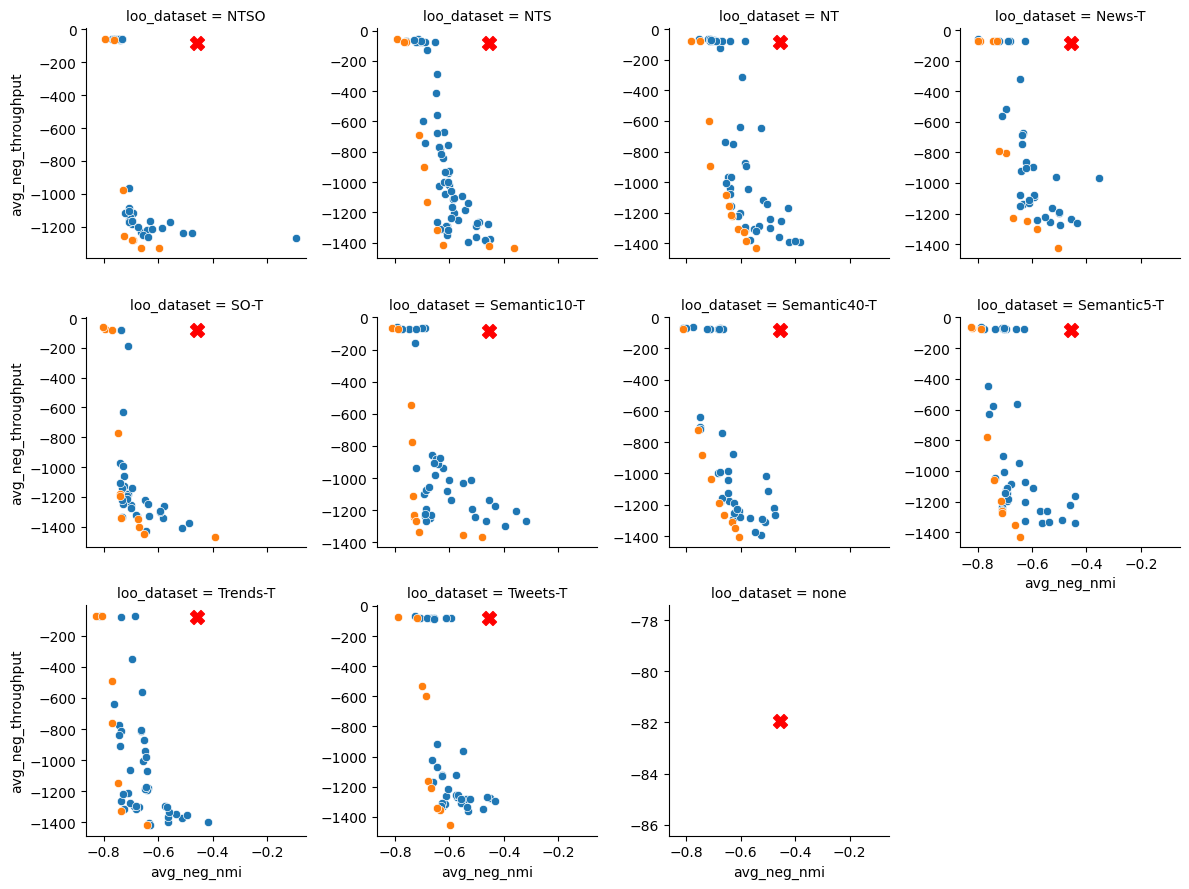

In [50]:
# Compute Pareto front per fold
df = avg_performance_train.copy()

g = sns.FacetGrid(df, col="loo_dataset", col_wrap=4, sharey=False, hue="is_pareto")
g.map(sns.scatterplot, "avg_neg_nmi", "avg_neg_throughput")

# Add default point
for ax, ds in zip(g.axes, df["loo_dataset"].unique()):
    default_point = df[df["config"] == "default"]
    if not default_point.empty:
        ax.scatter(default_point["avg_neg_nmi"], default_point["avg_neg_throughput"], color="red", label="default", marker="X", s=100)

<Axes: xlabel='avg_neg_nmi', ylabel='avg_neg_throughput'>

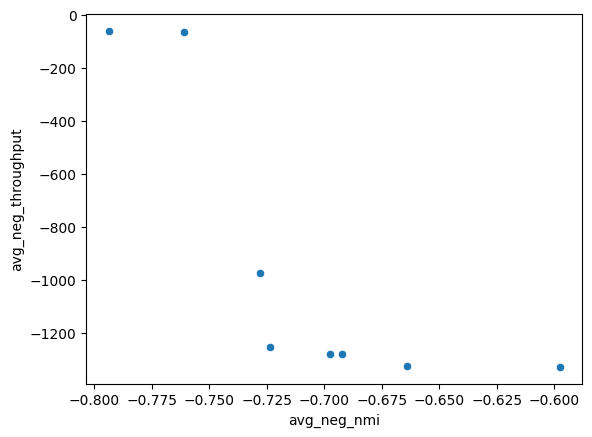

In [53]:
df = avg_performance_train.copy()
df = df[(df["loo_dataset"] == "NTSO") & (df["config"] != "default") & (df["is_pareto"] == True)]

sns.scatterplot(df, x="avg_neg_nmi", y="avg_neg_throughput")

In [48]:
# Assess performance for test folds
performance_on_train_test = avg_performance_train[avg_performance_train["is_pareto"]].copy()
performance_on_train_test = performance_on_train_test[performance_on_train_test["config"] != "default"].copy()
performance_on_train_test = performance_on_train_test.rename(columns={"loo_dataset": "dataset", "avg_neg_nmi": "neg_nmi_train", "avg_neg_throughput": "neg_throughput_train"})

d = df_full[["config", "config_id", "dataset", "neg_nmi", "neg_throughput"]].rename(columns={"neg_nmi": "neg_nmi_test", "neg_throughput": "neg_throughput_test"})


performance_on_train_test = performance_on_train_test.merge(d, on=["config", "config_id", "dataset"], how="left")
performance_on_train_test.head()

,config,config_id,dataset,neg_nmi_train,neg_throughput_train,is_pareto,neg_nmi_test,neg_throughput_test
0,best_config_loo_NTSO_seed_0.json,1,NTSO,-0.793654,-60.983073,True,-0.866675,-48.217282
1,best_config_loo_NTSO_seed_2.json,0,NTSO,-0.760717,-64.208866,True,-0.266754,-56.801431
2,best_config_loo_NTSO_seed_6.json,3,NTSO,-0.727756,-975.314051,True,-0.329575,-591.783787
3,best_config_loo_NTSO_seed_8.json,1,NTSO,-0.597603,-1329.341788,True,-0.078424,-1326.865019
4,best_config_loo_NTSO_seed_8.json,2,NTSO,-0.723641,-1256.060188,True,-0.340288,-1180.193972


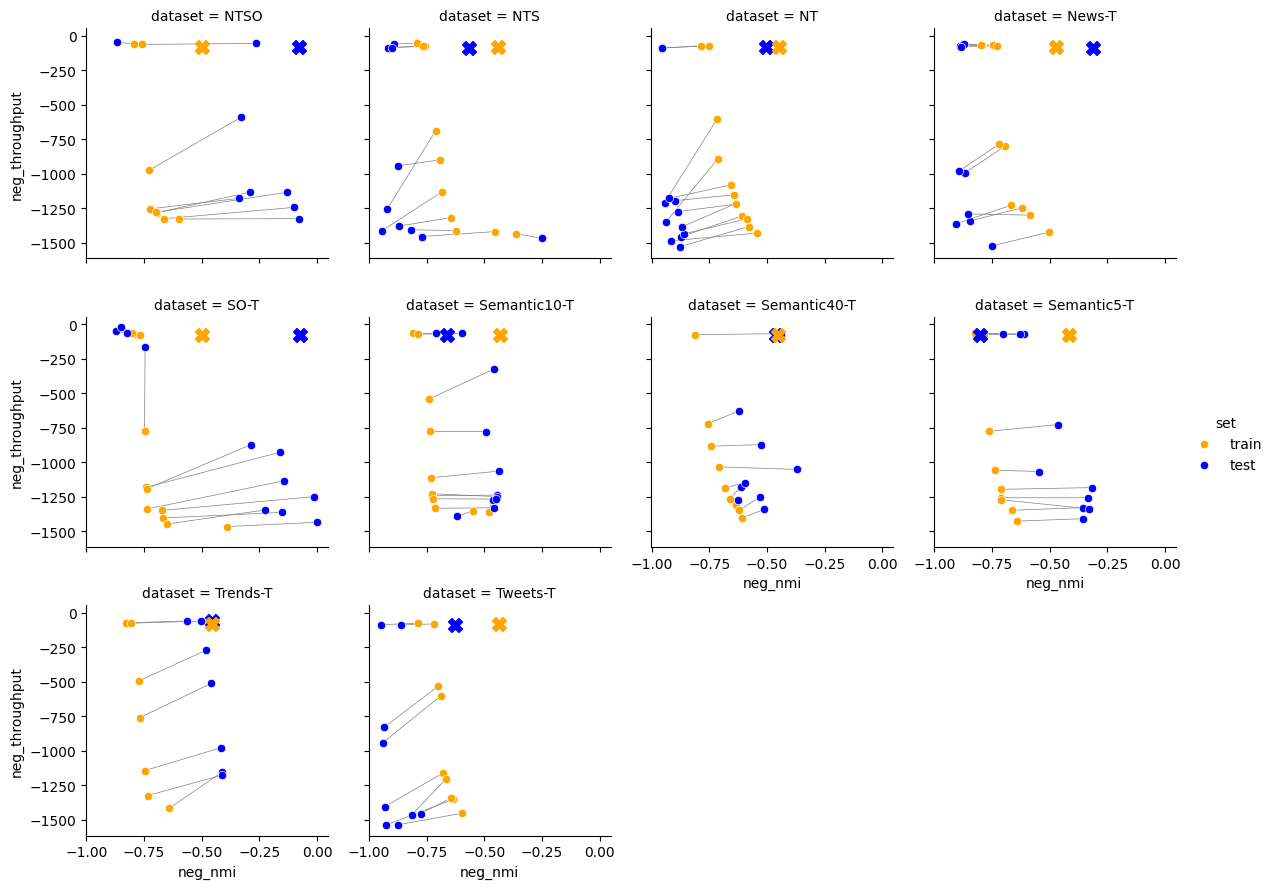

In [49]:
df = performance_on_train_test.copy()
df = pd.wide_to_long(df, stubnames=["neg_nmi", "neg_throughput"], i=["config", "config_id", "dataset"], j="set", sep="_", suffix=r"\w+").reset_index()

g = sns.FacetGrid(df, col="dataset", col_wrap=4, hue="set", palette={"train": "orange", "test": "blue"})
g.map(sns.scatterplot, "neg_nmi", "neg_throughput")

# Add lines
for ax, dataset in zip(g.axes.flat, g.col_names):
    facet_data = df[df["dataset"] == dataset]
    for config_id, group in facet_data.groupby(["config", "config_id"]):
        if len(group) == 2:
            ax.plot(group["neg_nmi"], group["neg_throughput"], color="gray", linewidth=0.5, zorder=0)

# Add default point
for ax, ds in zip(g.axes, df["dataset"].unique()):
    default_point = df_default[df_default["dataset"] == ds]
    #avg_performance_train[avg_performance_train["config"] == "default"]
    if not default_point.empty:
        ax.scatter(default_point["neg_nmi"], default_point["neg_throughput"], color="blue", label="default", marker="X", s=100)
        
    default_point_train = (df_default[df_default["dataset"] != ds][["neg_nmi", "neg_throughput"]]).mean()
    
    if not default_point_train.empty:
        ax.scatter(default_point_train["neg_nmi"], default_point_train["neg_throughput"], color="orange", label="default (train)", marker="X", s=100)
        

g.add_legend()

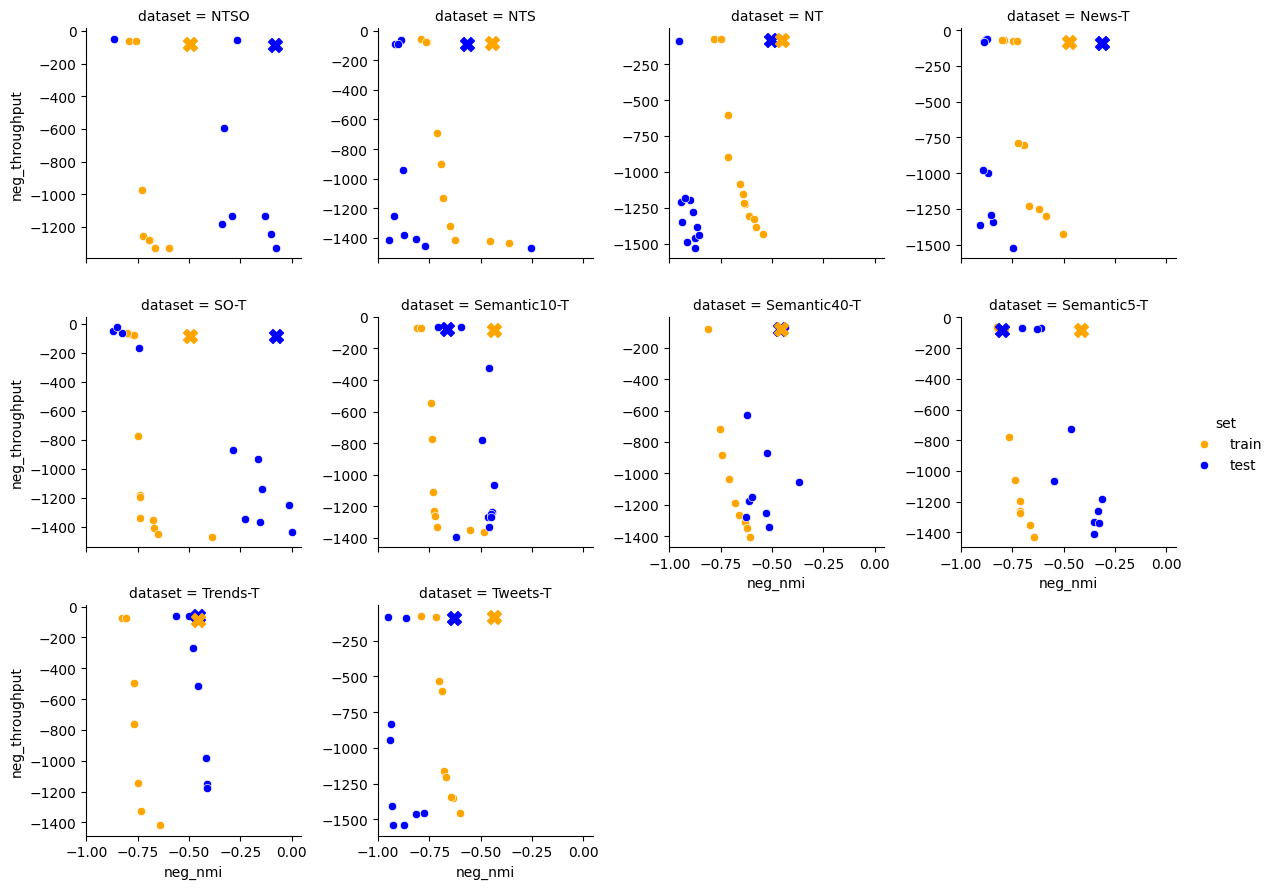

In [16]:
df = performance_on_train_test.copy()
df = pd.wide_to_long(df, stubnames=["neg_nmi", "neg_throughput"], i=["config", "config_id", "dataset"], j="set", sep="_", suffix=r"\w+").reset_index()

g = sns.FacetGrid(df, col="dataset", col_wrap=4, sharey=False, hue="set", palette={"train": "orange", "test": "blue"})
g.map(sns.scatterplot, "neg_nmi", "neg_throughput")
# Add legend
g.add_legend()

# Add default point
for ax, ds in zip(g.axes, df["dataset"].unique()):
    default_point = df_default[df_default["dataset"] == ds]
    #avg_performance_train[avg_performance_train["config"] == "default"]
    if not default_point.empty:
        ax.scatter(default_point["neg_nmi"], default_point["neg_throughput"], color="blue", label="default", marker="X", s=100)
        
    default_point_train = (df_default[df_default["dataset"] != ds][["neg_nmi", "neg_throughput"]]).mean()
    
    if not default_point_train.empty:
        ax.scatter(default_point_train["neg_nmi"], default_point_train["neg_throughput"], color="orange", label="default (train)", marker="X", s=100)
        
        
# TODO
# Rerun with 2 tweets per second. Just use 30_000 tweets per data set
# Validation on whole data set 
# Log of throughput

## Differences in configurations

In [17]:
import json

pareto_configs_df = avg_performance_train[avg_performance_train["config"] != "default"].copy()
pareto_configs_df = pareto_configs_df[pareto_configs_df["is_pareto"] == True].sort_values(by=["config"])

pareto_configs = []

for c, id, avg_neg_nmi, avg_neg_throughput in pareto_configs_df[["config", "config_id", "avg_neg_nmi", "avg_neg_throughput"]].values:
    with open(f"smac3_results/{c}", "r") as f:
        configs = json.load(f)
        config = configs[id]
        config["config_id"] = id
        config["config"] = c
        config["avg_neg_nmi"] = avg_neg_nmi
        config["avg_neg_throughput"] = avg_neg_throughput
        pareto_configs.append(config)

pareto_configs

[{'adaptive_threshold': 0,
  'clean_interval': 418,
  'cluster_interval': 2139,
  'decay_rate': 0.0132517745433,
  'min_num_mc': 26,
  'model': 'sentenceTransformers',
  'use_heuristic': 0,
  'min_weight': 0.0061354221649,
  'radius': 0.461543001203,
  'config_id': 1,
  'config': 'best_config_loo_NTSO_seed_0.json',
  'avg_neg_nmi': -0.7936540168777769,
  'avg_neg_throughput': -60.983072879941574},
 {'adaptive_threshold': 1,
  'clean_interval': 376,
  'cluster_interval': 2820,
  'decay_rate': 0.0089117471301,
  'min_num_mc': 6,
  'model': 'sentenceTransformers',
  'use_heuristic': 1,
  'sigma': 2.3874277330838,
  'threshold_momentum': 0.8273855722045,
  'time_gap': 1371.4299428111672,
  'config_id': 0,
  'config': 'best_config_loo_NTSO_seed_2.json',
  'avg_neg_nmi': -0.7607165876996228,
  'avg_neg_throughput': -64.20886596584553},
 {'adaptive_threshold': 1,
  'clean_interval': 383,
  'cluster_interval': 1189,
  'decay_rate': 0.0077520305401,
  'min_num_mc': 2,
  'model': 'minishlab',
  

In [18]:
config_df = pd.DataFrame(pareto_configs)
config_df.head(20)

,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,min_weight,radius,config_id,config,avg_neg_nmi,avg_neg_throughput,sigma,threshold_momentum,time_gap
0,0,418,2139,0.013252,26,sentenceTransformers,0,0.006135,0.461543,1,best_config_loo_NTSO_seed_0.json,-0.793654,-60.983073,NaN,NaN,NaN
1,1,376,2820,0.008912,6,sentenceTransformers,1,NaN,NaN,0,best_config_loo_NTSO_seed_2.json,-0.760717,-64.208866,2.387428,0.827386,1371.429943
2,1,383,1189,0.007752,2,minishlab,1,NaN,NaN,3,best_config_loo_NTSO_seed_6.json,-0.727756,-975.314051,2.798209,0.887677,828.737027
3,1,268,4590,0.011514,15,minishlab,0,0.109516,NaN,1,best_config_loo_NTSO_seed_8.json,-0.597603,-1329.341788,0.413823,0.437401,NaN
4,1,481,3994,0.006479,17,minishlab,0,0.390353,NaN,2,best_config_loo_NTSO_seed_8.json,-0.723641,-1256.060188,2.583216,0.587732,NaN
5,1,408,4201,0.005822,28,minishlab,1,NaN,NaN,0,best_config_loo_NTSO_seed_9.json,-0.692428,-1282.650640,2.109125,0.277396,37.603529
6,1,405,4376,0.005738,27,minishlab,1,NaN,NaN,1,best_config_loo_NTSO_seed_9.json,-0.663960,-1327.432509,1.119110,0.277396,416.873244
7,1,476,4172,0.005981,26,minishlab,1,NaN,NaN,2,best_config_loo_NTSO_seed_9.json,-0.697289,-1280.594566,2.130312,0.247110,472.476884
8,0,418,2139,0.013252,26,sentenceTransformers,0,0.006135,0.461543,0,best_config_loo_NTS_seed_0.json,-0.791105,-54.095863,NaN,NaN,NaN
9,0,132,503,0.002698,17,minishlab,1,NaN,0.449855,7,best_config_loo_NTS_seed_2.json,-0.694249,-901.331845,NaN,NaN,52.328381


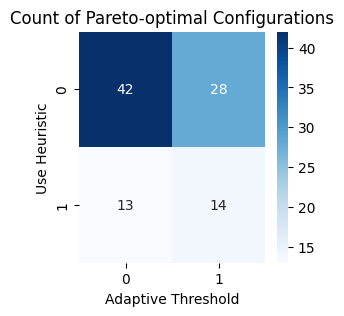

In [19]:
# Heatmap with adaptive threshold and use heuristic
# Count occurences
heatmap_data = config_df.groupby(["use_heuristic", "adaptive_threshold"]).size().unstack(fill_value=0)
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")
plt.title("Count of Pareto-optimal Configurations")
plt.xlabel("Adaptive Threshold")
plt.ylabel("Use Heuristic")
plt.gcf().set_size_inches(3, 3)
plt.show()

(23, 13)


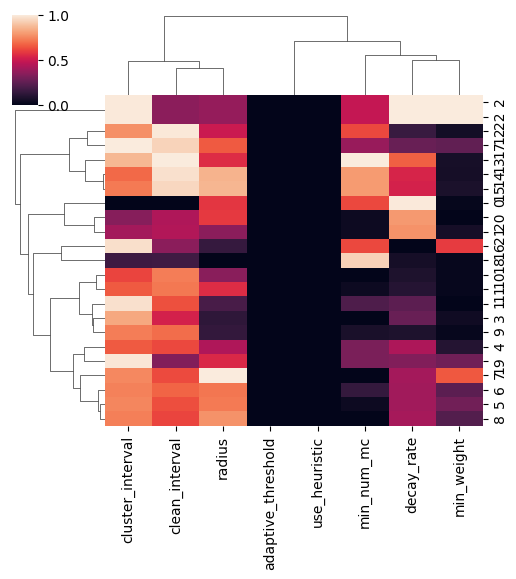

In [20]:
# Hierarchical clustering of configurations based on their parameters
from scipy.cluster.hierarchy import dendrogram
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import AgglomerativeClustering

#config_sentenceTrans = config_df[config_df['model'] == 'sentenceTransformer'].copy()
subset = config_df[(config_df['model'] == 'minishlab') & (config_df['use_heuristic']== False) & (config_df['adaptive_threshold']== False)].copy()
# Drop NA columns
subset = subset.dropna(axis=1, how="all")
print(subset.shape)

scaler = MinMaxScaler()
subset = subset.drop(columns=["config_id", "config", "model", "avg_neg_nmi", "avg_neg_throughput"])
subset_scaled = scaler.fit_transform(subset)
subset_scaled = pd.DataFrame(subset_scaled, columns=subset.columns)

clustering = AgglomerativeClustering(n_clusters=None, distance_threshold=0.0)
clustering = clustering.fit(subset_scaled)

sns.clustermap(subset_scaled, method='ward', metric='euclidean')
plt.gcf().set_size_inches(5, 5)
plt.show()

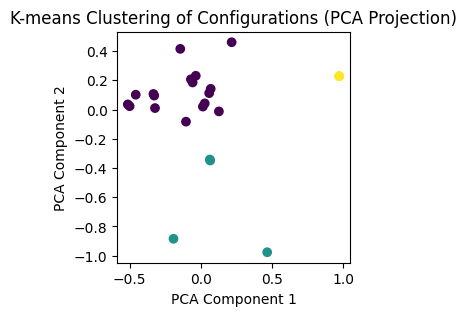

In [21]:
# k-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=123, n_init=100).fit(subset_scaled)

#Visualize using PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
subset_pca = pca.fit_transform(subset_scaled)

plt.scatter(subset_pca[:, 0], subset_pca[:, 1], c=kmeans.labels_)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("K-means Clustering of Configurations (PCA Projection)")
plt.gcf().set_size_inches(3, 3)
plt.show()

In [22]:
d = subset_scaled.copy()
d["cluster"] = pd.Categorical(kmeans.labels_)

d.groupby("cluster").agg([ "mean", "std"])

adaptive_threshold      clean_interval           cluster_interval  \
                      mean  std           mean       std             mean   
cluster                                                                     
0                      0.0  0.0       0.704635  0.206598         0.788733   
1                      0.0  0.0       0.259848  0.214894         0.226654   
2                      0.0  0.0       0.351515  0.000000         0.994853   

                  decay_rate           min_num_mc           use_heuristic  \
              std       mean       std       mean       std          mean   
cluster                                                                     
0        0.125387   0.310992  0.186271   0.312373  0.333091           0.0   
1        0.182128   0.654587  0.411805   0.405172  0.446393           0.0   
2        0.000000   1.000000  0.000000   0.482759  0.000000           0.0   

             min_weight              radius            
         std       mean       std      mean       std  
cluster                                                
0        0.0   0.173980  0.197205  0.535079  0.275217  
1        0.0   0.022603  0.024102  0.378986  0.275686  
2        0.0   1.000000  0.000000  0.373726  0.000000

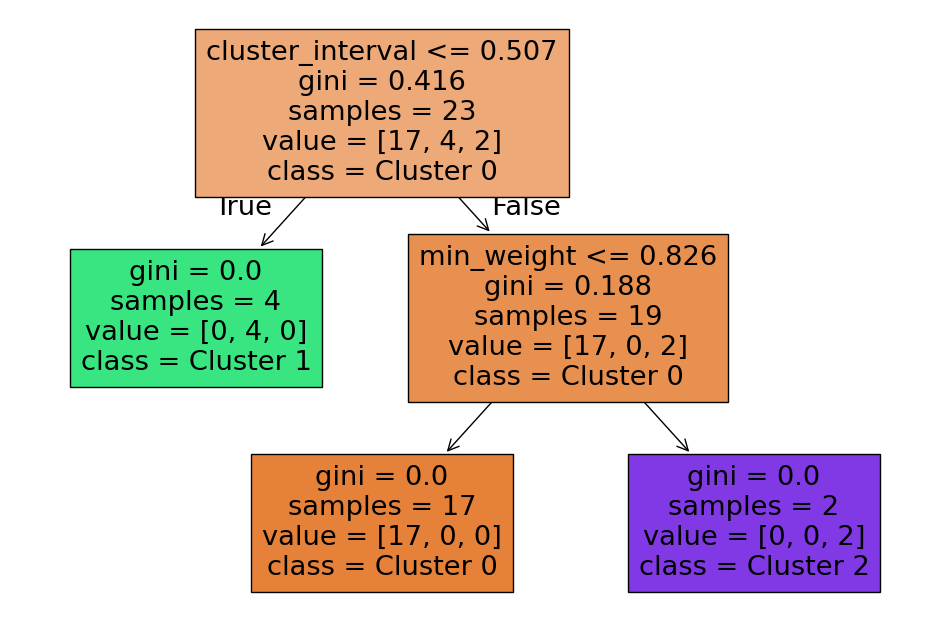

In [23]:
# Build decision tree to predict cluster labels based on configuration parameters
from sklearn.tree import DecisionTreeClassifier, plot_tree
X = subset_scaled.drop(columns=["use_heuristic", "adaptive_threshold"])
y = d["cluster"]
tree = DecisionTreeClassifier().fit(X, y)
plt.figure(figsize=(12, 8))
plot_tree(tree, feature_names=X.columns, class_names=[f"Cluster {i}" for i in range(len(set(y)))], filled=True)
plt.show()

In [24]:
print("Adaptive Threshold Values:")
print(config_df.adaptive_threshold.value_counts())

print("Models:")
print(config_df.model.value_counts())

print("Use heuristic:")
print(config_df.use_heuristic.value_counts())

Adaptive Threshold Values:
adaptive_threshold
0    55
1    42
Name: count, dtype: int64
Models:
model
minishlab               73
sentenceTransformers    24
Name: count, dtype: int64
Use heuristic:
use_heuristic
0    70
1    27
Name: count, dtype: int64


<Axes: xlabel='avg_neg_nmi', ylabel='avg_neg_throughput'>

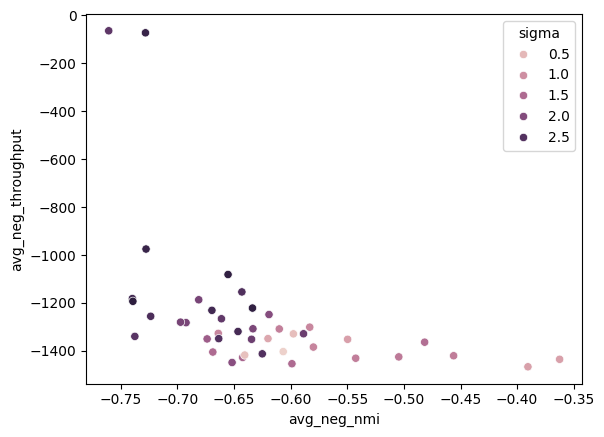

In [25]:
sns.scatterplot(config_df, x="avg_neg_nmi", y="avg_neg_throughput", hue="sigma")

<Axes: xlabel='avg_neg_nmi', ylabel='avg_neg_throughput'>

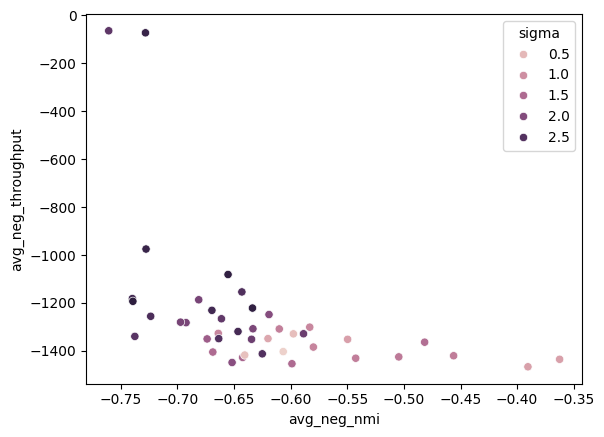

In [26]:
sns.scatterplot(config_df, x="avg_neg_nmi", y="avg_neg_throughput", hue="sigma")

### Analyze all outputs

In [20]:
from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import pandas as pd


_LOO_FOLDER_RE = re.compile(r"loo_(?P<loo_dataset>.+?)_seed_(?P<seed>[^/\\]+)")
_THROUGHPUT_RE = re.compile(r"Throughput\s+(?P<throughput>[0-9]*\.?[0-9]+)")


def _extract_metadata_from_path(path: Path) -> tuple[str | None, int | str | None]:
    for part in path.parts:
        match = _LOO_FOLDER_RE.fullmatch(part)
        if match:
            seed = match.group("seed")
            return match.group("loo_dataset"), int(seed) if seed.isdigit() else seed

    return None, None


def _extract_theoretical_throughput(additional_info: Any) -> float | None:
    if not isinstance(additional_info, dict):
        return None

    for key in ("error", "traceback"):
        value = additional_info.get(key)
        if not isinstance(value, str):
            continue

        match = _THROUGHPUT_RE.search(value)
        if match:
            return float(match.group("throughput"))

    return np.nan


def _flatten_configuration(configuration: Any) -> dict[str, Any]:
    if isinstance(configuration, dict):
        return dict(configuration)
    return {}


def _expand_costs(costs: Any) -> dict[str, Any]:
    if isinstance(costs, list):
        return {f"cost_{index + 1}": cost for index, cost in enumerate(costs)}
    if costs is None:
        return {}
    return {"cost_1": costs}


def runhistory_to_dataframe(runhistory_path: str | Path) -> pd.DataFrame:
    """Read one SMAC runhistory file into a flat dataframe.

    Each configuration option becomes its own column and each cost becomes its own column.
    """

    runhistory_path = Path(runhistory_path)
    loo_dataset, seed = _extract_metadata_from_path(runhistory_path)

    with runhistory_path.open() as file_handle:
        runhistory = json.load(file_handle)

    configs = runhistory.get("configs", {})
    rows: list[dict[str, Any]] = []

    for i, run in enumerate(runhistory.get("data", [])):
        config_id = run.get("config_id")
        config_key = str(config_id)
        configuration = configs.get(config_key, configs.get(config_id, {}))

        row = {
            "config_path": str(runhistory_path),
            "config_id": config_id,
            "run_index": i,
            "instance": run.get("instance"),
            "seed": seed,
            "loo_dataset": loo_dataset,
            "theoretical_throughput": _extract_theoretical_throughput(run.get("additional_info")),
        }
        row.update(_flatten_configuration(configuration))
        row.update(_expand_costs(run.get("cost")))
        rows.append(row)

    return pd.DataFrame(rows)


def runhistory_folder_to_dataframe(root_folder: str | Path) -> pd.DataFrame:
    """Read all runhistory files below a SMAC output root into one dataframe."""

    root_folder = Path(root_folder)
    runhistory_files = sorted(root_folder.rglob("runhistory.json"))

    if not runhistory_files:
        return pd.DataFrame(
            columns=["config_id", "instance", "seed", "loo_dataset", "theoretical_throughput", "run_index", "config_path"]
        )

    frames = [runhistory_to_dataframe(runhistory_file) for runhistory_file in runhistory_files]
    return pd.concat(frames, ignore_index=True)

runhistory_df = runhistory_folder_to_dataframe("smac3_output")
runhistory_df = runhistory_df.rename(columns={"cost_1": "neg_nmi", "cost_2": "neg_throughput"})

runhistory_df.head()

,config_path,config_id,run_index,instance,seed,loo_dataset,theoretical_throughput,adaptive_threshold,clean_interval,cluster_interval,...,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,neg_nmi,neg_throughput,min_weight,radius
0,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,0,examples/data/Trends-T.json,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.857247,-3.917407,NaN,NaN
1,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,1,examples/data/Semantic40-T.json,0,NTSO,NaN,1,100,1000,...,5,sentenceTransformers,1,1.0,0.5,1000.0,-0.306003,-4.089985,NaN,NaN
2,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,2,examples/data/Semantic40-T.json,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.520827,-4.193964,0.01,NaN
3,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,3,examples/data/Trends-T.json,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.790788,-3.949290,0.01,NaN
4,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,4,examples/data/News-T.json,0,NTSO,NaN,1,118,3149,...,22,sentenceTransformers,0,1.0,0.5,NaN,-0.763932,-4.229502,0.01,NaN


In [21]:
runhistory_df["theoretical_throughput"].mean()

np.float64(1.667277227722772)

In [22]:
runhistory_df["theoretical_throughput"].dtype

dtype('float64')

<Axes: xlabel='theoretical_throughput'>

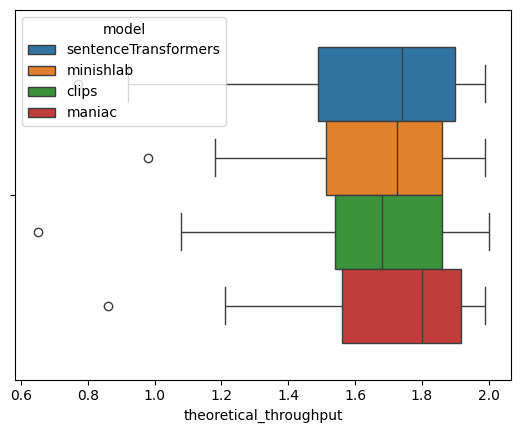

In [23]:
sns.boxplot(data=runhistory_df, x="theoretical_throughput", hue="model", fill=True)

instance
examples/data/Semantic40-T.json    322
examples/data/Trends-T.json        316
examples/data/Tweets-T.json        308
examples/data/Semantic10-T.json    303
examples/data/NT.json              298
examples/data/Semantic5-T.json     282
examples/data/News-T.json          275
examples/data/SO-T.json            270
examples/data/NTS.json             241
examples/data/NTSO-T.json          197
Name: count, dtype: int64
model
minishlab               756
maniac                  723
clips                   692
sentenceTransformers    641
Name: count, dtype: int64


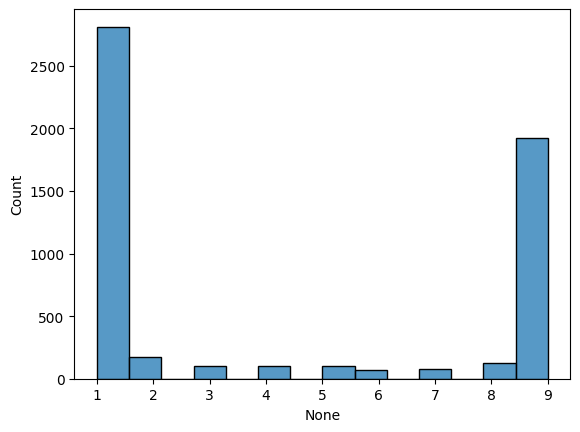

In [24]:
sns.histplot(x=runhistory_df.groupby(["config_path", "config_id"]).size())

unique_runs = runhistory_df.groupby(["config_path", "config_id"]).size().reset_index()
unique_runs = unique_runs[unique_runs[0] == 1]

unique_runs = unique_runs.merge(runhistory_df.drop_duplicates(), on=["config_path", "config_id"], how="left")

print(unique_runs["instance"].value_counts())
print(unique_runs["model"].value_counts())

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'examples/data/Trends-T.json'),
  Text(1, 0, 'examples/data/Semantic40-T.json'),
  Text(2, 0, 'examples/data/News-T.json'),
  Text(3, 0, 'examples/data/NT.json'),
  Text(4, 0, 'examples/data/Tweets-T.json'),
  Text(5, 0, 'examples/data/Semantic5-T.json'),
  Text(6, 0, 'examples/data/Semantic10-T.json'),
  Text(7, 0, 'examples/data/NTS.json'),
  Text(8, 0, 'examples/data/SO-T.json'),
  Text(9, 0, 'examples/data/NTSO-T.json')])

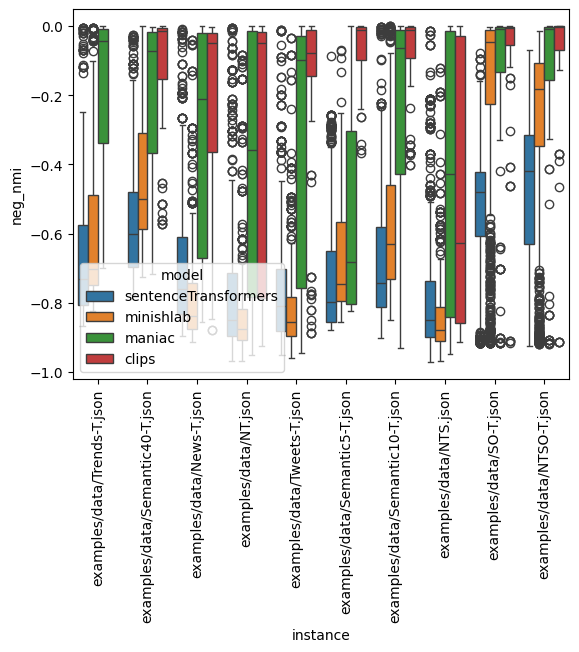

In [25]:
d = runhistory_df.copy()
d = d[d["neg_nmi"] != 2.0]
sns.boxplot(d, x="instance", y="neg_nmi", hue="model")
# Rotate x labels
plt.xticks(rotation=90)

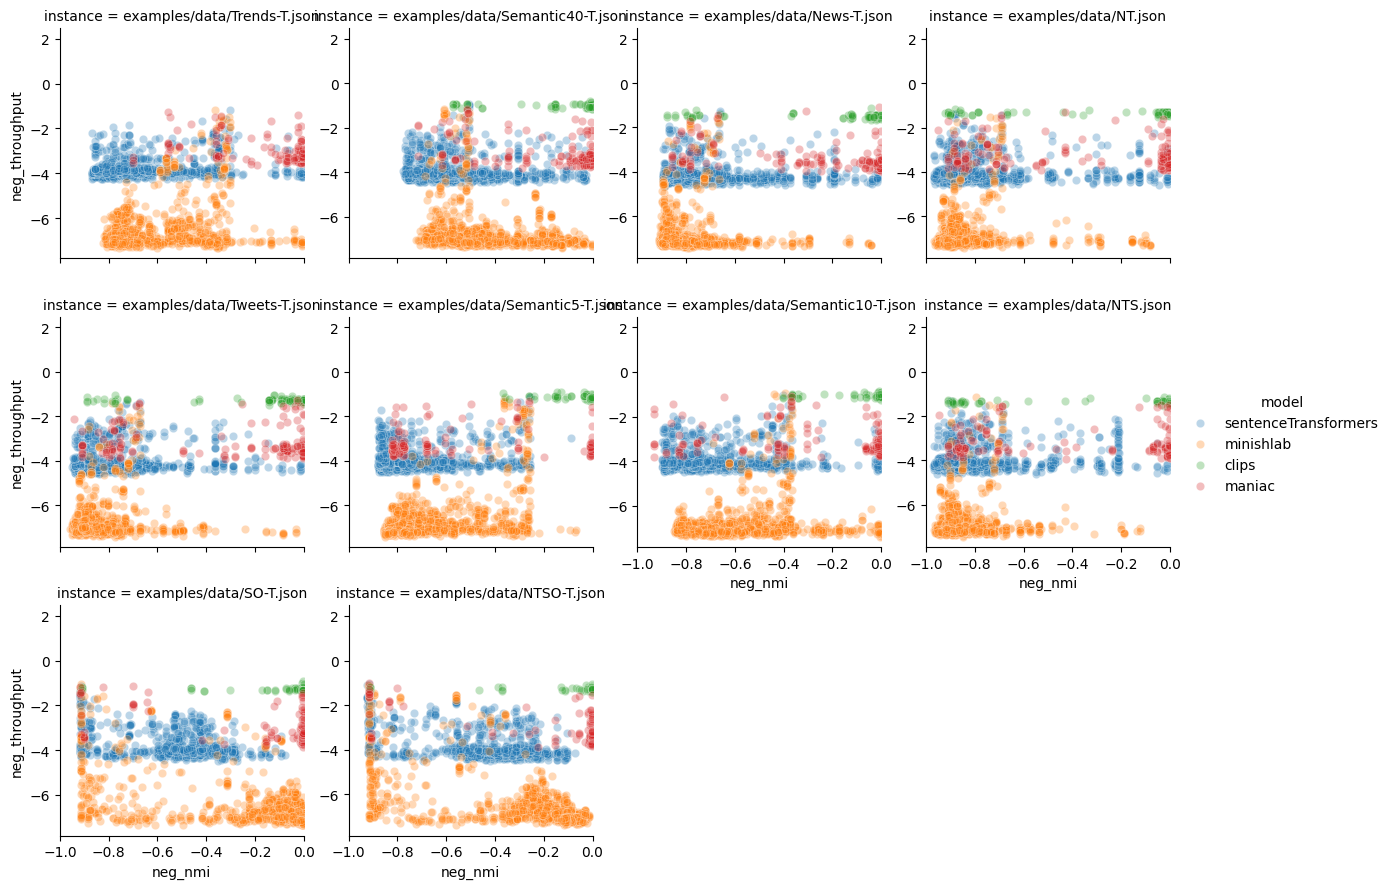

In [36]:
d = runhistory_df.copy()
g = sns.FacetGrid(d, col="instance", col_wrap=4, sharey=False, hue="model")
g.map(sns.scatterplot, "neg_nmi", "neg_throughput", alpha=0.3)
g.add_legend()
# Add limits 
g.set(xlim=(-1.0, 0.0))
g

In [27]:
# Add column that indicates wheather a configuration is on the Pareto front of the training performance
avg_performance_runhistory = runhistory_df.copy()
avg_performance_runhistory.loc[~np.isnan(avg_performance_runhistory["theoretical_throughput"]), "neg_throughput"] = -np.log(avg_performance_runhistory.loc[~np.isnan(avg_performance_runhistory["theoretical_throughput"]), "theoretical_throughput"])

avg_performance_runhistory = avg_performance_runhistory.groupby(by = ["config_path", "config_id"]).agg(
    avg_neg_nmi=("neg_nmi", "mean"),
    avg_neg_throughput=("neg_throughput", "mean"),
    set_size = ("instance", "size")
).reset_index()

configs = runhistory_df.drop(columns=["neg_nmi", "neg_throughput", "run_index", "instance", "theoretical_throughput"]).drop_duplicates()

avg_performance_runhistory = avg_performance_runhistory.merge(configs, on=["config_path", "config_id"], how="left")

avg_performance_runhistory.head(10)

config_list = ["adaptive_threshold", "clean_interval", "cluster_interval", "decay_rate", "min_num_mc", "model", "use_heuristic", "sigma", "threshold_momentum", "time_gap", "min_weight", "radius"]

# avg_performance_runhistory["is_pareto"] = (
#     avg_performance_runhistory[config_list]
#     .apply(tuple, axis=1)
#     .isin(config_df[config_list].apply(tuple, axis=1))
# )

avg_performance_runhistory.head()

,config_path,config_id,avg_neg_nmi,avg_neg_throughput,set_size,seed,loo_dataset,adaptive_threshold,clean_interval,cluster_interval,decay_rate,min_num_mc,model,use_heuristic,sigma,threshold_momentum,time_gap,min_weight,radius
0,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,1,-0.581625,-4.003696,2,0,NTSO,1,100,1000,0.000500,5,sentenceTransformers,1,1.000000,0.5,1000.0,NaN,NaN
1,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,2,-0.722472,-4.195313,9,0,NTSO,1,118,3149,0.011115,22,sentenceTransformers,0,1.000000,0.5,NaN,0.010000,NaN
2,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,3,2.000000,-0.431782,1,0,NTSO,0,196,2140,0.000431,17,sentenceTransformers,0,NaN,NaN,NaN,0.010000,0.2
3,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,4,2.000000,-0.553885,1,0,NTSO,0,100,640,0.000782,5,minishlab,0,NaN,NaN,NaN,0.007428,0.2
4,smac3_output/loo_NTSO_seed_0/60d7d3e335a182516...,5,-0.543082,-7.126957,9,0,NTSO,1,434,2046,0.020373,28,minishlab,1,0.948071,0.5,1000.0,NaN,NaN


(-1.0, 0.0)

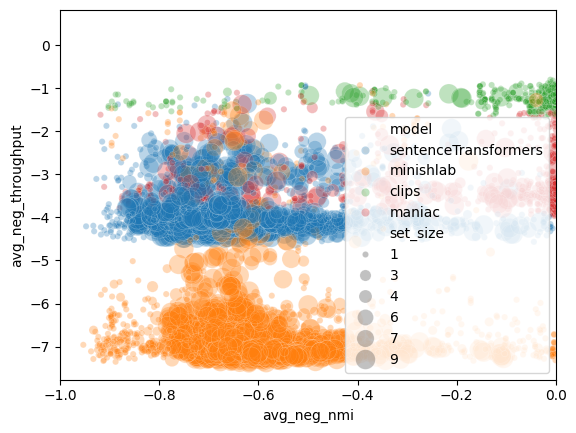

In [ ]:
sns.scatterplot(avg_performance_runhistory, x="avg_neg_nmi", y="avg_neg_throughput", hue="model", alpha=0.3, size="set_size", sizes=(20, 200))
#Add log scale
#plt.yscale("log")
# set x limits
plt.xlim(-1.0, 0.0)
#plt.yscale("symlog")

# TODO Why were so many good configurations not further tested?

(-1.0, 0.0)

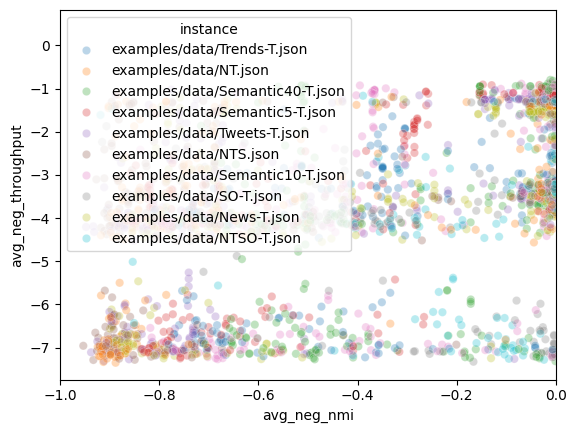

In [33]:
d = avg_performance_runhistory[avg_performance_runhistory["set_size"] == 1].copy()
d = d.merge(runhistory_df, how="left")
sns.scatterplot(d, x="avg_neg_nmi", y="avg_neg_throughput", hue="instance", alpha=0.3)
plt.xlim(-1.0, 0.0)